In [29]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from tqdm import tqdm
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# load MNIST dataset using pytorch
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081))]) #mean, std dev

cuda


In [30]:
train_set = datasets.MNIST('./data', train=True, download=True, transform=transform)
test_set = datasets.MNIST('./data', train=False, download=True, transform=transform)

In [31]:
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=64, shuffle=True)

### Block 2: Inception Modules

In [32]:
class Inception(nn.Module):
    def __init__(self, in_channels, c1, c2, c3, c4):
        super().__init__()
        self.b1 = nn.Sequential(nn.Conv2d(in_channels, c1, kernel_size=1), nn.ReLU())
        self.b2 = nn.Sequential(
            nn.Conv2d(in_channels, c2[0], kernel_size=1), nn.ReLU(),
            nn.Conv2d(c2[0], c2[1], kernel_size=3, padding=1), nn.ReLU()
        )
        self.b3 = nn.Sequential(
            nn.Conv2d(in_channels, c3[0], kernel_size=1), nn.ReLU(),
            nn.Conv2d(c3[0], c3[1], kernel_size=5, padding=2), nn.ReLU()
        )
        self.b4 = nn.Sequential(
            nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
            nn.Conv2d(in_channels, c4, kernel_size=1), nn.ReLU()
        )
    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)

In [33]:
class GoogLeNetMNIST(nn.Module):
    def __init__(self):
        super(GoogLeNetMNIST, self).__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, 64, kernel_size=3, padding=1), nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2))

        #Inception 3a and 3b
        self.inception3 = nn.Sequential(Inception(64, 64, (96, 128), (16, 32), 32),
        Inception(256, 128, (128, 192), (32, 96), 64),
        nn.MaxPool2d(kernel_size=2, stride=2)
        )

        #Inception 4a, 4e
        self.inception4 = nn.Sequential(Inception(480, 192, (96, 208), (16, 48), 64),
        Inception(512, 160, (112, 224), (24, 64), 64),
        Inception(512, 128, (128, 256), (24, 64), 64),
        Inception(512, 112, (144, 288), (32, 64), 64),
        Inception(528, 256, (160, 320), (32, 128), 128),
        nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.avgpool = nn.AdaptiveAvgPool2d((1,1))
        self.dropout = nn.Dropout(0, 4)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(832, 10)
        
    def forward(self, x):
        x = self.stem(x)
        x = self.inception3(x)
        x = self.inception4(x)
        x = self.avgpool(x)
        x = self.flatten(x)
        x = self.dropout(x)
        return self.fc(x)

In [34]:
def train_model(model, train_loader, optimizer, criterion, epochs=10):
    losses, accs = [], []
    model.train()
    for epoch in range(epochs):
        running_loss = 0.0
        correct = 0
        total = 0
        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=False)
        for data, target in loop:
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * data.size(0)
            preds = output.argmax(dim=1)
            correct += (preds == target).sum().item()
            total += data.size(0)

            loop.set_postfix(loss=running_loss/total, acc=100.0*correct/total)

        epoch_loss = running_loss / total
        epoch_acc = 100.0 * correct / total
        losses.append(epoch_loss); accs.append(epoch_acc)

    return losses, accs

def plot_results(losses, accs, model, loader):
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.plot(losses)
    plt.title('Training Loss')
    plt.xlabel('Epochs')
    plt.ylabel(losses)

    plt.subplot(1, 2, 2)
    plt.plot(accs)
    plt.title('Training Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.show()

    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for data, target in loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            y_true.extend(target.cpu().numpy())
            y_pred.extend(output.argmax(dim=1).cpu().numpy())
    
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

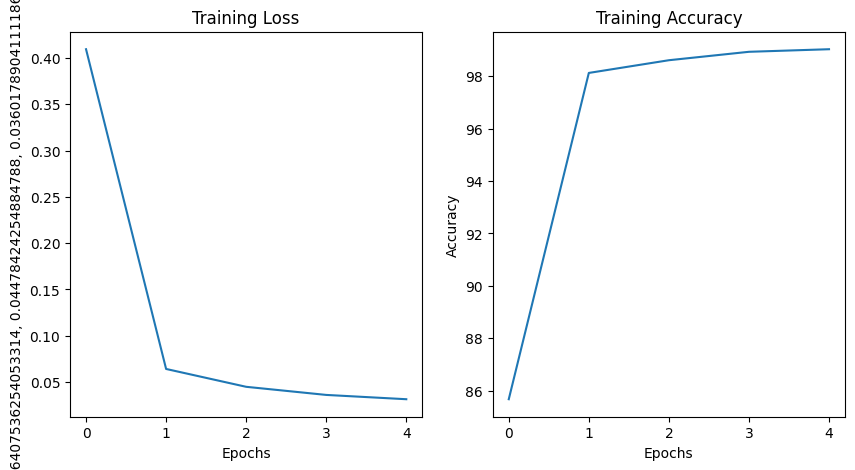

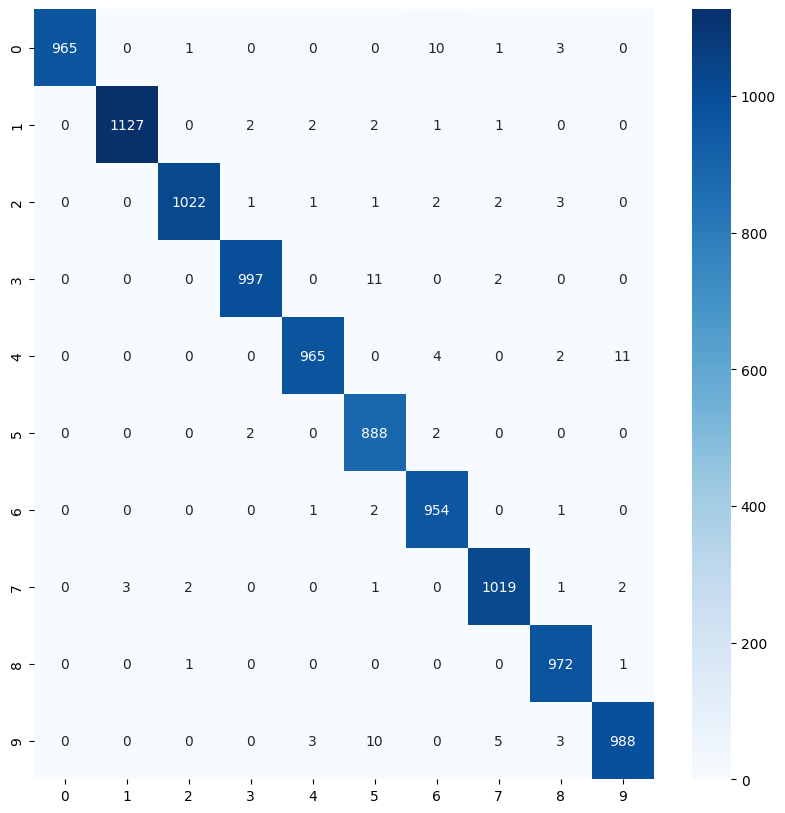

In [35]:
model = GoogLeNetMNIST().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)
criterion = nn.CrossEntropyLoss()

history_loss, history_acc = train_model(model, train_loader, optimizer, criterion, epochs = 5)
plot_results(history_loss, history_acc, model, test_loader)